In [ ]:
from langchain_core.messages import HumanMessage , SystemMessage , AIMessage
from langgraph.graph import StateGraph , START ,END
from langchain_openai import ChatOpenAI
import operator
from langchain_ollama import ChatOllama
from pydantic import BaseModel , Field
from typing import TypedDict , Annotated , Literal
from dotenv import load_dotenv
import os




In [ ]:
load_dotenv
api_key = os.getenv("YOUR_API_KEY")

In [ ]:
# model selection 

# this is local model for ollama install before in your local machine then this code will be executed
llm = ChatOllama(
    model="gemma4:12b",
    temperature=0.2,
    num_predict=100,
    reasoning=False
)

# CHATGPT
# This model work with enter api key or openai model

# llm = ChatOpenAI(model = "model name",api_key=api_key,temperature=0.4)


In [56]:
# with structure output find 
class StructureReview(BaseModel):
      evaluation: Literal["approved", "needs_improvement"] = Field(..., description="Final evaluation result.")
      feedback : str = Field(...,description="feedback for the tweet.")



In [57]:
# structure output 


strcture_eval = llm.with_structured_output(StructureReview)

In [58]:
#create state 
class TweetState(TypedDict):

    topic : str
    tweet : str
    evaluation: Literal["approved", "needs_improvement"]
    feedback : str
    iteration : int
    max_iteration : int

    feedback_history : Annotated[list[str],operator.add]
    tweet_history: Annotated[list[str], operator.add]

In [59]:
#tweet node function
def tweet_generator(state : TweetState) -> TweetState:

        # prompt
    messages = [
        SystemMessage(content="You are a funny and clever Twitter/X influencer."),
        HumanMessage(content=f"""
Write a short, original, and hilarious tweet on the topic: "{state['topic']}".

Rules:
- Do NOT use question-answer format.
- Max 280 characters.
- Use observational humor, irony, sarcasm, or cultural references.
- Think in meme logic, punchlines, or relatable takes.
- Use simple, day to day english
""")
    ]

    # send generator_llm
    response = llm.invoke(messages).content

    # return response
    return {'tweet': response, 'tweet_history': [response]}

In [60]:
def evaluation_generator (state : TweetState) -> TweetState:

    messages = [
        SystemMessage(content="You are a ruthless, no-laugh-given Twitter critic. You evaluate tweets based on humor, originality, virality, and tweet format."),
        HumanMessage(content=f"""
        Evaluate the following tweet:

        Tweet: "{state['tweet']}"

        Use the criteria below to evaluate the tweet:

        1. Originality – Is this fresh, or have you seen it a hundred times before?  
        2. Humor – Did it genuinely make you smile, laugh, or chuckle?  
        3. Punchiness – Is it short, sharp, and scroll-stopping?  
        4. Virality Potential – Would people retweet or share it?  
        5. Format – Is it a well-formed tweet (not a setup-punchline joke, not a Q&A joke, and under 280 characters)?

        Auto-reject if:
        - It's written in question-answer format (e.g., "Why did..." or "What happens when...")
        - It exceeds 280 characters
        - It reads like a traditional setup-punchline joke
        - Dont end with generic, throwaway, or deflating lines that weaken the humor (e.g., “Masterpieces of the auntie-uncle universe” or vague summaries)

        ### Respond ONLY in structured format:
        - evaluation: "approved" or "needs_improvement"  
        - feedback: One paragraph explaining the strengths and weaknesses 
        """)
            ]

    response = strcture_eval.invoke(messages)

    return {'evaluation':response.evaluation, 'feedback': response.feedback, 'feedback_history': [response.feedback]}


In [61]:
def optimize_generator(state:TweetState) -> TweetState:

    messages = [
        SystemMessage(content="You punch up tweets for virality and humor based on given feedback."),
        HumanMessage(content=f"""
Improve the tweet based on this feedback:
"{state['feedback']}"

Topic: "{state['topic']}"
Original Tweet:
{state['tweet']}

Re-write it as a short, viral-worthy tweet. Avoid Q&A style and stay under 280 characters.
""")
    ]

    response = llm.invoke(messages).content
    iteration = state['iteration'] + 1

    return {'tweet': response, 'iteration': iteration, 'tweet_history': [response]}


In [62]:
def route_evaluation(state : TweetState) -> TweetState:

    if state['evaluation'] == 'approved' or state['iteration'] >= state['max_iteration']:
        return 'approved'
    else:
        return 'needs_improvement'


In [63]:
#object of state 
graph = StateGraph(TweetState)

In [64]:
# create node to execute flow of state
graph.add_node('tweet_generator',tweet_generator)
graph.add_node('evaluation',evaluation_generator)
graph.add_node('optimize',optimize_generator)



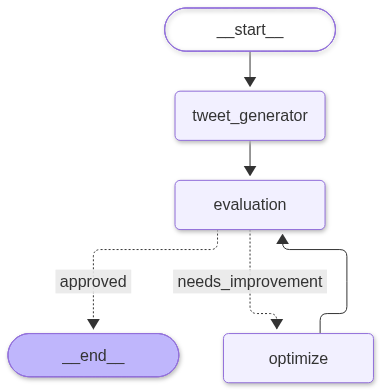

In [65]:
# add node with edge
graph.add_edge(START , 'tweet_generator')
graph.add_edge('tweet_generator' , 'evaluation')

graph.add_conditional_edges('evaluation',route_evaluation,{'approved':END , 'needs_improvement' : 'optimize'})

graph.add_edge('optimize','evaluation')


# workflow 

workflow = graph.compile()


from IPython.display import Image

Image(workflow.get_graph().draw_mermaid_png())



In [68]:
initial_state = {
    "topic": "ai",
    "iteration": 1,
    "max_iteration": 5
}
result = workflow.invoke(initial_state)

KeyboardInterrupt: 

In [ ]:


result
    


{'topic': 'srhberhb',
 'tweet': 'Since the feedback is basically telling you to stop "explaining" the joke and just "be" the joke, we need to strip away every single word of meta-commentary. \n\nThe goal is to make the tweet feel like a glitch in the matrix or a moment of pure, unhinged chaos.\n\nHere are three ways to do it:\n\n**Option 1: The "Pure Chaos" (High Virality)**\n> srhberhb\n\n**Option 2',
 'evaluation': 'needs_improvement',
 'feedback': "This isn't a tweet; it's a meta-commentary on the process of making a tweet, which is the exact opposite of the 'be the joke' instruction provided in the text. You are over-explaining the mechanics of humor instead of executing it. While 'srhberhb' has a microscopic chance of being perceived as 'unhinged chaos,' the surrounding preamble is bloated, dry,",
 'iteration': 5,
 'max_iteration': 5,
 'feedback_history': ["The tweet relies on a tired '3 AM brain' trope that has been exhausted on the timeline for years. While the internal monologu